# Real estate portfolio screening with Cotality and CARTO MCPs

**SDSC 2026 workshop · follow-along notebook**

We take a portfolio of about 1,000 properties in south Lee County, Florida, and the address list is messy.
In Section 1 we clean it up and add climate risk, using the results of the same Cotality MCP calls that we demonstrate
live. In Section 2 we load the data into CARTO and ask a map's AI agent where our
properties sit relative to new growth and climate risk.

| Part | What you do |
|---|---|
| 0 · Setup | Install anything missing, find the data, and (optional) connect Claude |
| 1 · Profile | How messy is the address list? |
| 2 · Resolve | Every row to a Cotality property ID (CLIP); duplicates collapse |
| 3 · Climate risk | Property-level climate risk for every CLIP: **checkpoint 1** |
| 4 · Into CARTO | Upload the data (browser or Claude), set up the map's AI agent, ask questions |

**Everyone follows this notebook.** It runs every step on the full, pre-computed results. If you also have
Claude with the workshop connectors, the **Try it in Claude** boxes let you repeat a few of the presenters'
live MCP calls yourself. They're optional, but if you have access to Claude chat, we would recommend trying out the Connectors.

**Reference docs in this repo**

- [README](https://github.com/eprashar-clgx/sdsc-2026-re-portfolio-screening#readme): workshop overview and setup
- [DATA.md](https://github.com/eprashar-clgx/sdsc-2026-re-portfolio-screening/blob/main/DATA.md): every file and column
- [mcp/cotality_on_claude.md](https://github.com/eprashar-clgx/sdsc-2026-re-portfolio-screening/blob/main/mcp/cotality_on_claude.md): connect the Cotality MCP server to Claude
- [mcp/carto_on_claude.md](https://github.com/eprashar-clgx/sdsc-2026-re-portfolio-screening/blob/main/mcp/carto_on_claude.md): connect the CARTO MCP server to Claude
- [maps/README.md](https://github.com/eprashar-clgx/sdsc-2026-re-portfolio-screening/blob/main/maps/README.md): build the map in CARTO
- [maps/agent_instructions.md](https://github.com/eprashar-clgx/sdsc-2026-re-portfolio-screening/blob/main/maps/agent_instructions.md): the agent's Use Case and Instructions
- [maps/prompts.md](https://github.com/eprashar-clgx/sdsc-2026-re-portfolio-screening/blob/main/maps/prompts.md): questions to ask the map agent, with expected answers
- [semantic_models/README.md](https://github.com/eprashar-clgx/sdsc-2026-re-portfolio-screening/blob/main/semantic_models/README.md): the agent's semantic model

Run the cells top to bottom (**Shift + Enter**). Each finishes in a few seconds.

## 0 · Setup

**Options to run this:**

- **A clone of this repo in VS Code:** set up the environment once (see the
  [README](https://github.com/eprashar-clgx/sdsc-2026-re-portfolio-screening#readme)), then choose the
  `.venv` kernel: **Select Kernel → Python Environments → .venv**. The notebook reads the repo's `data/` folder.
- **Google Colab, with the code pasted in:** everything is already installed. The cell below installs
  anything missing, and the next one downloads the data files into your Colab session. Colab deletes them when
  the session ends: if you come back later, run the cells from the top again.

In [1]:
import importlib.util
import subprocess
import sys

for module, package in (("pandas", "pandas"), ("pyarrow", "pyarrow"), ("shapely", "shapely"),
                        ("matplotlib", "matplotlib")):
    if importlib.util.find_spec(module) is None:
        print(f"installing {package} ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package])
print("packages ready")

packages ready


In [2]:
import math
import os
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import shapely
from matplotlib.collections import PolyCollection

GITHUB_REPO = "eprashar-clgx/sdsc-2026-re-portfolio-screening"
REPO_URL = os.environ.get("PORTFOLIO_REPO_URL", f"https://raw.githubusercontent.com/{GITHUB_REPO}/main/")
FILES = ["portfolio_messy.csv", "portfolio_truth.csv", "portfolio_matches.parquet", "portfolio_risk.parquet",
         "growth_h3_r9.parquet", "growth_parcels.parquet", "parcel_essentials.parquet"]


def find_data():
    """Use data/ from a clone of the repo if there is one; otherwise download the files from GitHub."""
    for folder in (Path("data"), Path("../data")):
        if all((folder / f).exists() for f in FILES):
            print(f"using the data in {folder}/")
            return folder
    folder = Path("data")
    folder.mkdir(exist_ok=True)
    for f in FILES:
        if not (folder / f).exists():
            print(f"downloading {f} ...")
            urllib.request.urlretrieve(REPO_URL + "data/" + f, folder / f)
    print(f"data saved in {folder}/")
    return folder


def read_table(name):
    """Read a CSV or (Geo)Parquet file. The binary geometry column of GeoParquet files is left out."""
    if name.endswith(".csv"):
        return pd.read_csv(DATA / name, dtype={"truth_clip": str})
    return pd.read_parquet(DATA / name).drop(columns="geometry", errors="ignore")


def read_shapes(name):
    """Read a GeoParquet file with its geometry as shapes (GeoParquet stores it as WKB bytes)."""
    df = pd.read_parquet(DATA / name)
    df["geometry"] = shapely.from_wkb(df["geometry"])
    return df


DATA = find_data()
pd.set_option("display.max_colwidth", 70)

using the data in ..\data/


> **Try it in Claude (optional): set up.** You need Claude in your browser ([claude.ai](https://claude.ai)) with
> a plan that supports custom connectors.
>
> 1. **Connectors:** add the **Cotality** connector with the workshop URL and key shown on screen
>    ([mcp/cotality_on_claude.md](https://github.com/eprashar-clgx/sdsc-2026-re-portfolio-screening/blob/main/mcp/cotality_on_claude.md)),
>    and, for part 4, the **CARTO** connector
>    ([mcp/carto_on_claude.md](https://github.com/eprashar-clgx/sdsc-2026-re-portfolio-screening/blob/main/mcp/carto_on_claude.md)).
> 2. **New chat:** start a new chat for the workshop. Click **+ → Connectors** and turn on Cotality (and CARTO
>    later). Turn other connectors off, so Claude doesn't reach for the wrong tool.
> 3. **Model:** the default Sonnet model is fine and fastest. Extended thinking or research is not needed for our tasks, although feel free to try > after the workshop.
> 4. **Budget:** the Cotality key is shared by the whole room. The prompts below use **8 Cotality calls in
>    total** (7 address lookups, 1 climate risk lookup). Please don't ask Claude to process the whole list:
>    that's what the cached results in this notebook are for.
> 5. **Check the work:** Claude shows each tool call it makes. Click one to see the request it sent and the
>    raw response, then compare its answer with the cached result the notebook prints.

## 1 · Profile: how messy is the list?

`portfolio_messy.csv` is the list as you'd receive it: one address per row, typed by different people over
the years. How far do a few rules of thumb get you?

In [3]:
messy = read_table("portfolio_messy.csv")
print(f"{len(messy):,} rows")
messy.sample(8, random_state=4)

1,147 rows


,input_id,address
582,583,"27296 Gasparilla Drv, Bonita Springs, FL 34135"
221,222,"25250 Divot Dr, Bonita Springs, FL 34135"
265,266,"10130 Northridge Ct, Estero, FL 34135"
154,155,"23231 Sanabria Loop, Bonita Springs, FL"
518,519,"10037 Idle Pine Ln, Estero, FL 34135"
617,618,"95777 Sunshine Dr, Bonita Springs, FL 34135"
98,99,"23328 Saanabria Loop, Bonita Springs, FL 34135"
325,326,"28900 Bermuda Pointe Cir, Bonita Springs, FL 34134"


In [4]:
address = messy["address"]
normalized = (address.str.lower()
              .str.replace(r"[^a-z0-9 ]", " ", regex=True)
              .str.replace(r"\b\d{5}\b\s*$", "", regex=True)
              .str.replace(r"\s+", " ", regex=True).str.strip())
flags = pd.DataFrame({
    "no ZIP code": ~address.str.contains(r"\b\d{5}\.?\s*$"),
    "case, spacing or punctuation": (address.ne(address.str.strip()) | address.str.contains("  ")
                                     | address.eq(address.str.lower()) | ~address.str.contains(",")
                                     | address.str.contains(r"\.")),
    "no house number": ~address.str.strip().str.match(r"^\d"),
    "same text as another row": normalized.duplicated(keep=False),
})
summary = flags.sum().sort_values(ascending=False).rename("rows flagged").to_frame()
summary["share"] = (summary["rows flagged"] / len(messy)).map("{:.0%}".format)
print(f"rows with at least one flag: {flags.any(axis=1).mean():.0%}")
summary

rows with at least one flag: 20%


,rows flagged,share
"case, spacing or punctuation",121,11%
no ZIP code,93,8%
same text as another row,37,3%
no house number,20,2%


The rules flag about one row in five. They catch formatting problems and missing ZIP codes, but miss typos,
abbreviations, wrong cities and most duplicates, which are typed differently each time. The answer key,
`portfolio_truth.csv`, shows what was actually done to each row: nearly two thirds have a problem.

In [5]:
truth = read_table("portfolio_truth.csv")
mix = truth["error_type"].value_counts().rename("rows").to_frame()
mix["share"] = (mix["rows"] / len(truth)).map("{:.0%}".format)
print(f"rows with an error: {(truth['error_type'] != 'clean').mean():.0%}    "
      f"duplicate rows: {truth['is_duplicate'].sum()}    rows with no real property: "
      f"{(truth['error_type'] == 'unmatchable').sum()}")
mix

rows with an error: 64%    duplicate rows: 117    rows with no real property: 30


,rows,share
error_type,,
clean,414,36%
abbreviation,171,15%
typo,116,10%
zip,115,10%
case_punct,114,10%
unit,103,9%
wrong_city,67,6%
unmatchable,30,3%
alternate_address,17,1%


### Example of where a generic LLM can go wrong: abbreviations

Testing this list with Gemini Pro 3.1, we asked the LLM to find "abbreviation problems" in this list and it flagged most of rows. But
**Dr, Ln, Cir, Blvd and Ct are the standard USPS forms**: an address written that way is correct. The genuine
problems are addresses that depart from the standard: "10101 Maddox Lane" and "10101 Maddox La" are the same
house as "10101 Maddox Ln", but as text they don't match, so joins and lookups miss them. The cell below
separates the two.

In [6]:
STANDARD = r"\b(?:Dr|Ln|Cir|Ct|Rd|Blvd|St|Ave|Ter|Pkwy|Pl|Trl)\b"
SPELLED_OUT = {"Drive", "Lane", "Circle", "Court", "Road", "Boulevard", "Street", "Avenue", "Terrace", "Parkway",
               "Place", "Trail", "Grove", "Bend", "North", "South", "East", "West"}

abbr = truth[truth["error_type"] == "abbreviation"].copy()
abbr["changed_to"] = abbr["error_detail"].str.split(" -> ").str[1]
abbr["category"] = "Non-standard short form (Drv, La, Crt, Cr, Bl, Av)"
abbr.loc[abbr["changed_to"].isin(SPELLED_OUT), "category"] = "Spelled-out street type (Drive, Lane, Circle…)"
abbr.loc[abbr["changed_to"] == "Bonita Spgs", "category"] = "Non-standard city name (Bonita Spgs)"
standard = truth[truth["address"].str.contains(STANDARD, case=False, regex=True)
                 & (truth["error_type"] != "abbreviation")]

comparison = pd.DataFrame(
    [("Standard USPS abbreviation", len(standard), standard["address"].iloc[0].strip(),
      "No: correct form. A generic LLM's false positive")]
    + [(category, len(group), group["address"].iloc[0].strip(), "Yes: a genuine abbreviation error")
       for category, group in abbr.groupby("category")],
    columns=["Category", "Rows", "Example", "A problem?"])
print(f"rows with any abbreviation: {len(standard) + len(abbr):,}    genuine abbreviation errors: {len(abbr)}")
comparison

rows with any abbreviation: 1,022    genuine abbreviation errors: 171


,Category,Rows,Example,A problem?
0,Standard USPS abbreviation,851,"9772 Glen Heron Dr, Bonita Springs, FL 34135",No: correct form. A generic LLM's false positive
1,Non-standard city name (Bonita Spgs),12,"26871 Sammoset Way, Bonita Spgs, FL 34135",Yes: a genuine abbreviation error
2,"Non-standard short form (Drv, La, Crt, Cr, Bl, Av)",38,"24165 Sunny La, Bonita Springs, FL 34135",Yes: a genuine abbreviation error
3,"Spelled-out street type (Drive, Lane, Circle…)",121,"10600 Wood Ibis Avenue, Bonita Springs, FL 34135",Yes: a genuine abbreviation error


A model that counts every abbreviated row reports roughly 1,000 "abbreviation problems"; the genuine ones are
171. Nobody told it what "correct" means here, so it guesses, and produces false positives. Cotality's address
recognition knows the USPS standard, so it simply fixes the genuine errors: 99% of them resolve to the right
property (part 2). A more evolved model - say Opus 5.5 -  may get this right, but getting it right would need prior knowledge and/or the correct prompting

> **Try it in Claude (optional, no MCP calls).** Upload `data/portfolio_messy.csv` to your chat (paperclip
> or **+ → Add files**) and ask:
>
> *"Profile this address list: how many total rows, what kinds of problems do you see (missing ZIP codes, typos,
> abbreviations, formatting, missing unit numbers), what percentage of all rows have a problem, and roughly how
> many rows look like duplicates? Give me a short table with an example of each problem."*
>
> **Look for:**
> - **Abbreviations:** if the model reports hundreds of abbreviation problems, check its examples against the
>   table above. "Dr" or "Ln" are false positives; "Drive", "Drv" or "Bonita Spgs" are genuine.
> - **Duplicates:** it can spot rows typed two ways, but not the 17 duplexes in part 2, which have different
>   house numbers. The answer key has 117 duplicate rows.
> - **Overall:** the answer key above says 64% of rows have a problem.

## 2 · Resolve: one messy address in, one CLIP out

Now, let's send each address to Cotality's address recognition tool, `li-recognize_address`, through the
Cotality MCP. It returns the property's **CLIP** (Cotality's persistent property ID), a standardized address and a
**match score**. When it isn't sure (for example, a condo address without its unit number), it still returns its
best guess but flags it with a low score: those rows go to a **needs review** list instead of into your portfolio.
A second call, `clip-find_property_by_clip`, adds each property's location.

`portfolio_matches.parquet` holds the results for every row. Compare them with the answer key:

In [7]:
matches = read_table("portfolio_matches.parquet")
scored = matches.merge(truth[["input_id", "error_type", "is_duplicate", "truth_clip"]], on="input_id")
scored["outcome"] = "correct CLIP"
scored.loc[scored["match_status"] == "needs_review", "outcome"] = "needs review"
scored.loc[scored["match_status"] == "not_found", "outcome"] = "not found"
scored.loc[(scored["match_status"] == "matched") & (scored["clip"] != scored["truth_clip"]), "outcome"] = "wrong CLIP"

by_type = pd.crosstab(scored["error_type"], scored["outcome"], margins=True, margins_name="all rows")
by_type["% correct"] = (100 * by_type["correct CLIP"] / by_type["all rows"]).round(0)
pd.concat([by_type.drop(index="all rows").sort_values("% correct"), by_type.loc[["all rows"]]])

outcome,correct CLIP,needs review,not found,wrong CLIP,all rows,% correct
error_type,,,,,,
unmatchable,0,0,30,0,30,0.0
unit,44,56,0,3,103,43.0
typo,88,0,28,0,116,76.0
abbreviation,170,0,0,1,171,99.0
clean,410,4,0,0,414,99.0
wrong_city,66,1,0,0,67,99.0
case_punct,114,0,0,0,114,100.0
alternate_address,17,0,0,0,17,100.0
zip,115,0,0,0,115,100.0


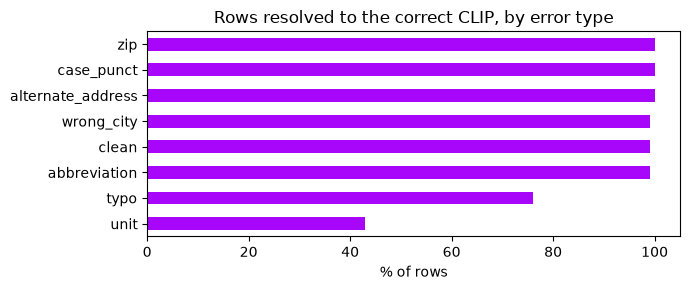

In [8]:
rates = by_type.drop(index="all rows")["% correct"].drop(index="unmatchable").sort_values()
ax = rates.plot.barh(figsize=(7, 3), color="#a805fb", title="Rows resolved to the correct CLIP, by error type")
ax.set_xlabel("% of rows"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

Formatting, abbreviations, a missing ZIP or a wrong city barely matter: address recognition fixes them. Typos
fail about one time in four. **A dropped unit number never gets a confident match**: in a condo building the
street address alone doesn't identify a unit, so the tool returns a low-scored guess and the row goes to
*needs review* (56 of the 60 such rows) instead of into your portfolio. All 30 fake addresses come back not
found, with no false matches.

> **Try it in Claude (optional, 5 Cotality calls).** The next cell prints the five addresses the presenters
> resolve live, and the cached answers. Paste this prompt into your Claude chat, with the five addresses
> underneath:
>
> *"Use the Cotality connector's li-recognize_address tool to standardize each of these 5 addresses, one call
> per address. Then show one table with: input address, standardized address, CLIP, match score, and match
> description (or 'not found'). Don't call any other tools."*
>
> **Look for:**
> - 4 addresses resolve and 1 comes back not found (the typo "Rosewpod").
> - The fixes: the missing ZIP is filled in, the typo "Whisspering" is corrected, and both wrong cities are
>   replaced (Estero → Bonita Springs, Bonita Springs → Naples).
> - Claude's CLIPs match the cached ones below: it's the same tool the cached results came from.

In [11]:
DEMO_IDS = [517, 1132, 167, 958, 262]
print("Addresses to paste into Claude:\n")
print("\n".join(messy.set_index("input_id").loc[DEMO_IDS, "address"].str.strip()))
print("\nCached answers to compare with:")
(matches.set_index("input_id").loc[DEMO_IDS, ["input_address", "match_status", "clip", "resolved_address",
                                              "match_confidence", "address_match_description"]])

Addresses to paste into Claude:

24381 copperleaf blvd, estero, fl 34135
10101 Maddox Ln #202, Bonita Springs, FL
29120 Brendisi Way #3201, Bonita Springs, FL 34110
23090 Whisspering Ridge Dr, Estero, FL 34135
26670 Rosewpod Pointe Cir #202, Bonita Springs, FL 34135

Cached answers to compare with:


,input_address,match_status,clip,resolved_address,match_confidence,address_match_description
input_id,,,,,,
517,"24381 copperleaf blvd, estero, fl 34135",matched,1001923644,24381 COPPERLEAF BLVD BONITA SPRINGS FL 34135-8403,10.0,Matched unique number
1132,"10101 Maddox Ln #202, Bonita Springs, FL",matched,3663466958,10101 MADDOX LN APT 202 BONITA SPRINGS FL 34135-7641,10.0,"Matched unique number, postcode changed"
167,"29120 Brendisi Way #3201, Bonita Springs, FL 34110",matched,4327889120,29120 BRENDISI WAY # 3201 NAPLES FL 34110-2843,9.0,"Matched unique number, multiple match resolved by address or locat..."
958,"23090 Whisspering Ridge Dr, Estero, FL 34135",matched,4605213063,23090 WHISPERING RIDGE DR BONITA SPRINGS FL 34135-8419,10.0,"Matched unique number, street name changed"
262,"26670 Rosewpod Pointe Cir #202, Bonita Springs, FL 34135",not_found,NaN,NaN,NaN,NaN


### Duplicates only the CLIP can catch

Some duplicates can't be spotted by reading the list. 17 properties are **multi-property/unit parcels**: one property with two front
doors, listed once under each house number. They look like next-door neighbours, yet both resolve to the same CLIP:

In [9]:
matched = scored[scored["match_status"] == "matched"]
print(f"{len(scored):,} rows  ->  {len(matched):,} matched  ->  {matched['clip'].nunique():,} unique properties (CLIPs)")
print(f"needs review: {(scored['match_status'] == 'needs_review').sum()}    "
      f"not found: {(scored['match_status'] == 'not_found').sum()}")
dupes = scored[scored["is_duplicate"]]
print(f"duplicate rows resolved to the right property: {(dupes['outcome'] == 'correct CLIP').sum()} of {len(dupes)}")

1,147 rows  ->  1,028 matched  ->  931 unique properties (CLIPs)
needs review: 61    not found: 58
duplicate rows resolved to the right property: 113 of 117


In [10]:
duplex = scored[scored["error_type"] == "alternate_address"][["truth_clip", "input_address", "clip"]]
print(f"second addresses that resolve to the property's CLIP: {(duplex['clip'] == duplex['truth_clip']).sum()} of {len(duplex)}")
first = scored[scored["truth_clip"].isin(duplex["truth_clip"]) & (scored["error_type"] != "alternate_address")]
first = first[first["clip"].notna()].drop_duplicates("truth_clip")[["truth_clip", "input_address", "clip"]]
pairs = first.merge(duplex, on="truth_clip", suffixes=(" (row 1)", " (row 2)"))
pairs["same property?"] = (pairs["clip (row 1)"] == pairs["clip (row 2)"]).map({True: "yes, one CLIP", False: "no"})
pairs[["input_address (row 1)", "input_address (row 2)", "clip (row 1)", "same property?"]].head(8)

second addresses that resolve to the property's CLIP: 17 of 17


,input_address (row 1),input_address (row 2),clip (row 1),same property?
0,"10065 Illiinois St, Bonita Springs, FL 34135","10067 Illinois St, Bonita Springs, FL 34135",1018743700,"yes, one CLIP"
1,"10290 Kentucky St, Bonita Springs, FL 34135","10292 Kentucky St, Bonita Springs, FL 34135",4328237106,"yes, one CLIP"
2,"3510 Brink Cir, Bonita Springs, FL","3512 Brink Cir, Bonita Springs, FL 34134",1029669600,"yes, one CLIP"
3,"4809 Gary Rd, Bonita Springs, FL","4811 Gary Rd, Bonita Springs, FL 34134",3727896878,"yes, one CLIP"
4,"27230 Mayfair Ct, Bonita Springs, FL 34135","27240 Mayfair Ct, Bonita Springs, FL 34135",3739736286,"yes, one CLIP"
5,"3879 Bennett Ln, Bonita Springs, FL 34134","3881 Bennett Ln, Bonita Springs, FL 34134",8414986009,"yes, one CLIP"
6,"4817 Gary Road, Bonita Springs, FL 34134","4819 Gary Rd, Bonita Springs, FL 34134",2673583606,"yes, one CLIP"
7,"10230 Kentucky St, Bonita Springs, FL 34135","10232 Kentucky St, Bonita Springs, FL 34135",8109621433,"yes, one CLIP"


> **Try it in Claude (optional, 2 Cotality calls).** Can the model tell these two rows are one property?
>
> 1. First, **without tools**: *"Are these two addresses the same property? 4817 Gary Road, Bonita Springs, FL
>    34134 and 4819 Gary Rd, Bonita Springs, FL 34134."*
> 2. Then: *"Now check with the Cotality connector's li-recognize_address tool, one call per address, and compare
>    the CLIPs."*
>
> **Look for:** without the tool, the model treats them as neighbours (different house numbers) or can't tell.
> With it, both return CLIP 2673583606: one property. That's a duplicate no amount of reading would find.

## 3 · Climate risk: checkpoint 1

Next, the presenters call the Cotality MCP tool `at-get_property_climate_risk` for each CLIP. It returns
scores for 12 perils, today and in 2030, 2040 and 2050 under four emissions scenarios. Scores run from 1 to
100 (higher is riskier) and rank a property against others of the same type.

`portfolio_risk.parquet` is the result: one row per property with its CLIP, location, H3 cell and the key
scores. **This is checkpoint 1**, the table you load into CARTO in part 4.

In [12]:
risk = read_table("portfolio_risk.parquet")
print(f"{len(risk):,} properties, {risk['risk_score'].notna().sum():,} with climate risk scores")
risk[["clip", "resolved_address", "risk_score", "cfl_score", "tcwi_score", "call_score_ssp5_85_2050"]].head()

931 properties, 928 with climate risk scores


,clip,resolved_address,risk_score,cfl_score,tcwi_score,call_score_ssp5_85_2050
0,2949614696,9772 GLEN HERON DR BONITA SPRINGS FL 34135-7773,84.0,91.0,51.0,88.0
1,4541898520,24080 COPPERLEAF BLVD BONITA SPRINGS FL 34135-8169,52.0,69.0,65.0,64.0
2,1049068367,28750 TRAILS EDGE BLVD UNIT 204 BONITA SPRINGS FL 34134-7525,6.0,57.0,39.0,23.0
3,8636560048,9353 LAKE ABBY LN BONITA SPRINGS FL 34135-8882,84.0,89.0,69.0,89.0
4,7972803451,23815 CLEAR SPRING CT APT 2105 BONITA SPRINGS FL 34135-3600,50.0,45.0,70.0,66.0


In [13]:
perils = {"call_score": "All perils", "tcwi_score": "Hurricane wind", "cfl_score": "Flood (inland + surge)",
          "flxx_score": "Inland flood", "tcfl_score": "Storm surge", "ceq_score": "Earthquake",
          "call_score_ssp5_85_2050": "All perils, 2050 (high emissions)"}
risk[list(perils)].rename(columns=perils).describe().loc[["mean", "25%", "50%", "75%"]].round(0).T

,mean,25%,50%,75%
All perils,55.0,36.0,59.0,74.0
Hurricane wind,68.0,54.0,71.0,77.0
Flood (inland + surge),64.0,52.0,67.0,75.0
Inland flood,49.0,28.0,55.0,66.0
Storm surge,29.0,18.0,25.0,40.0
Earthquake,7.0,5.0,7.0,7.0
"All perils, 2050 (high emissions)",68.0,54.0,73.0,84.0


Hurricane wind and flood drive most of the risk here, and the all-perils score rises by about 14 points by
2050 under high emissions. The map shows where the riskier properties are:

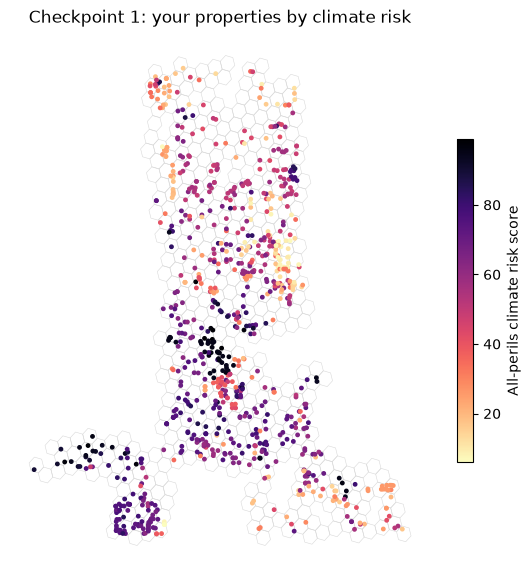

In [14]:
cells = read_shapes("growth_h3_r9.parquet")
fig, ax = plt.subplots(figsize=(7, 7))
ax.add_collection(PolyCollection([list(g.exterior.coords) for g in cells["geometry"]],
                                 facecolor="none", edgecolor="#d9d9d9", linewidth=0.4))
points = ax.scatter(risk["lon"], risk["lat"], c=risk["risk_score"], cmap="magma_r", s=6)
fig.colorbar(points, ax=ax, shrink=0.6, label="All-perils climate risk score")
ax.autoscale_view()
ax.set_aspect(1 / math.cos(math.radians(risk["lat"].mean())))  # keep distances true at this latitude
ax.set_title("Checkpoint 1: your properties by climate risk"); ax.set_axis_off()
plt.show()

> **Try it in Claude (optional, 1 Cotality call).** One property, one call. In the same chat, ask:
>
> *"Use the Cotality connector's at-get_property_climate_risk tool for CLIP 3663466958 only, in a single call.
> From today's scores (climate scenario BASE), report the averageAnnualLossRiskScore for CALL (all perils),
> CFL (flood) and TCWI (hurricane wind), and the CALL score in 2050 under SSP5_85. If the property has more
> than one climate record, use the highest score. Answer with a short table, then one sentence on what drives
> the risk."*
>
> **Look for:**
> - The scores match the cached row printed below: all perils 60, flood 48, hurricane wind 75, and 74 in 2050.
> - Hurricane wind is the main driver.
> - Open the tool call: the raw response is large (about 170 KB for one property: 12 perils × 13 scenario
>   years). That's why the presenters wrap the tool in a small summary tool of their own. If Claude struggles
>   with the size, ask for one peril at a time. Don't ask for several CLIPs at once.

In [15]:
risk.loc[risk["clip"] == "3663466958", ["clip", "resolved_address", "call_score", "cfl_score", "tcwi_score",
                                        "call_score_ssp5_85_2050"]]

,clip,resolved_address,call_score,cfl_score,tcwi_score,call_score_ssp5_85_2050
559,3663466958,10101 MADDOX LN APT 202 BONITA SPRINGS FL 34135-7641,60.0,48.0,75.0,74.0


## 4 · Into CARTO

Section 2 happens in CARTO Builder. You need four files from this repo's `data/` folder:

| File | What it is |
|---|---|
| `portfolio_risk.parquet` | Checkpoint 1: your 931 properties with climate risk |
| `growth_h3_r9.parquet` | 459 H3 cells with growth and risk measures |
| `growth_parcels.parquet` | 918 properties where new development is happening |
| `parcel_essentials.parquet` | Every parcel in the study area (about 12 MB) |

Load them with either option below, keeping each table's name the same as its file name
(`portfolio_risk`, `growth_h3_r9`, `growth_parcels`, `parcel_essentials`) and all four in the same dataset.

### Option A · In the browser

1. Download the four files: from your clone's `data/` folder, from this repo's `data/` folder on GitHub,
   or (in Colab) from the **Files** panel on the left.
2. In CARTO Workspace, open **Data Explorer** and click **Import data**.
3. Choose a file, then pick the **CARTO Data Warehouse** connection and your **private** dataset. Keep the
   suggested table name if it matches the file name; otherwise type it (for example `portfolio_risk`).
4. Repeat for the other three files.
5. Open one of the new tables and note its full name, shown at the top: `carto-dw-ac-xxxx.private_yourname_xxxx.portfolio_risk`.
   The part before the last dot is your **project and dataset**; you need it for the semantic model below.

### Option B · In Claude, with the CARTO MCP server

> **Try it in Claude (optional, CARTO calls only).**
>
> 1. Connect the CARTO connector: see
>    [mcp/carto_on_claude.md](https://github.com/eprashar-clgx/sdsc-2026-re-portfolio-screening/blob/main/mcp/carto_on_claude.md).
>    It signs in with your own CARTO account, so it doesn't use the shared Cotality key.
> 2. In your chat, click **+ → Connectors** and turn on CARTO.
> 3. Ask, with the four URLs from the next cell pasted underneath:
>
>    *"Using the CARTO connector, import these four GeoParquet files into my CARTO Data Warehouse private
>    dataset. Name each table exactly after its file name without the extension (portfolio_risk,
>    growth_h3_r9, growth_parcels, parcel_essentials). When they're done, list the full table names and row
>    counts."*
>
> **Look for:** four tables with 931, 459, 918 and 21,592 rows. `parcel_essentials` is the largest and takes
> longest. Note the full table name: everything before the last dot is your **project and dataset**.

In [16]:
for f in ("portfolio_risk.parquet", "growth_h3_r9.parquet", "growth_parcels.parquet", "parcel_essentials.parquet"):
    print(REPO_URL + "data/" + f)

https://raw.githubusercontent.com/eprashar-clgx/sdsc-2026-re-portfolio-screening/main/data/portfolio_risk.parquet
https://raw.githubusercontent.com/eprashar-clgx/sdsc-2026-re-portfolio-screening/main/data/growth_h3_r9.parquet
https://raw.githubusercontent.com/eprashar-clgx/sdsc-2026-re-portfolio-screening/main/data/growth_parcels.parquet
https://raw.githubusercontent.com/eprashar-clgx/sdsc-2026-re-portfolio-screening/main/data/parcel_essentials.parquet


### Set up the map and its AI agent

1. In Builder, create a map and add the tables as layers: `growth_h3_r9` (cells), `growth_parcels`, and
   `portfolio_risk` on top. `parcel_essentials` is optional on the map; the agent can query it either way.
2. Add an **AI agent** to the map and fill in:
   - **Use Case** and **Instructions**: copy them from
     [maps/agent_instructions.md](https://github.com/eprashar-clgx/sdsc-2026-re-portfolio-screening/blob/main/maps/agent_instructions.md).
   - **Capabilities**: turn on **Query sources** so the agent can run SQL.

   Leave the **semantic model** empty for now.

### Step 5: the same question, before and after the semantic model

1. **Before:** ask the agent *"Which of my properties sit in high-growth cells?"* Note how many properties it
   finds and how it got there (how did it link properties to cells? what counted as "high" growth?).
2. **Add the semantic model:** set `MY_DATASET` in the next cell to your project and dataset and run it. It
   writes `portfolio_screening_semantic_model.yaml`, with your tables filled in, next to this notebook (in
   Colab, it downloads it). Import that file in the agent's semantic model settings.
3. **After:** ask the exact same question again. Expected: **474 of your 931 properties** (238 in Pursue
   cells, 236 in Watchlist cells), every time you ask.

   More detail: [maps/README.md](https://github.com/eprashar-clgx/sdsc-2026-re-portfolio-screening/blob/main/maps/README.md)
   and [semantic_models/README.md](https://github.com/eprashar-clgx/sdsc-2026-re-portfolio-screening/blob/main/semantic_models/README.md).

In [17]:
MY_DATASET = "YOUR_PROJECT.YOUR_DATASET"  # e.g. "carto-dw-ac-abcd1234.private_jane_1a2b3c4d"

PLACEHOLDER = "YOUR_PROJECT.YOUR_DATASET"
source = Path("semantic_models/portfolio_screening.yaml")
if not source.exists():
    source = Path("../semantic_models/portfolio_screening.yaml")
if source.exists():
    model = source.read_text()
else:
    with urllib.request.urlopen(REPO_URL + "semantic_models/portfolio_screening.yaml") as response:
        model = response.read().decode()

if MY_DATASET == PLACEHOLDER:
    print("Set MY_DATASET above to your project and dataset, then run this cell again.")
else:
    out = Path("portfolio_screening_semantic_model.yaml")
    out.write_text(model.replace(PLACEHOLDER, MY_DATASET.strip().strip("`")))
    print(f"wrote {out} ({model.count(PLACEHOLDER)} table references set to {MY_DATASET})")
    try:
        from google.colab import files
        files.download(str(out))
    except ImportError:
        pass

Set MY_DATASET above to your project and dataset, then run this cell again.


### Ask the agent

With the semantic model in place, ask these in order. The expected answers come from the same data, so your
agent should match them.
[maps/prompts.md](https://github.com/eprashar-clgx/sdsc-2026-re-portfolio-screening/blob/main/maps/prompts.md) has more to try.

| Prompt | Expected answer |
|---|---|
| Which of my properties sit in high-growth cells? | Before the semantic model: it depends. After: 474 of 931 (238 Pursue, 236 Watchlist) |
| Classify the cells into Pursue, Watchlist, Hold and Reassess, and colour the map by quadrant. | Pursue 62 cells, Watchlist 158, Hold 158, Reassess 77, Unclassified 4 |
| For each quadrant, show the number of cells, my properties and growth parcels, the average growth parcels per cell, and the mix of growth stages. | Watchlist: 158 cells, 236 properties, 608 growth parcels |
| Which Watchlist properties have a lower property-level climate risk than their cell? | 47 of the 236 |

**Want to redo the live Cotality steps yourself?** Connect the Cotality MCP server to Claude:
[mcp/cotality_on_claude.md](https://github.com/eprashar-clgx/sdsc-2026-re-portfolio-screening/blob/main/mcp/cotality_on_claude.md).